> **Aktualizace, 24. října.** Nasazený model je nyní model s měřeními dělenými proudem plazmatu (`analysis/clean_model.py`, `results/clean-model.md`). Oddíly 1 až 8 a příloha hodnotí recepturu `cand`, předchozí nasazený model, s protokolem popsaným níže; oddíl „Nasazený model dnes“ (před přílohou) dává nový model vedle `cand` a základu na týchž 30 výbojích.

# 09 Nasazený model na výbojích, na kterých se nikdo neučil: konečné vyhodnocení

**Otázka.** Jak těsně se nasazený model shoduje s referenční rekonstrukcí ústavu na celých výbojích, na kterých se neučila žádná z jeho sítí, po parametrech,
v mm a kA, a jak moc se tomu číslu dá věřit?

**Receptura ve dvou řádcích** (`analysis/final_evaluation.py`, receptura `cand`). Síť na 24 magnetických vstupech plus 22 rozdílech sousedních cívek
(46 vstupů, 256-256-128, Huberova ztráta, 150 epoch), ridge regrese pro `plasma_current` a druhá síť učená jen na řádcích s limiterovým plazmatem,
která odpovídá `R_limiter` a `Z_limiter`, když první síť předpoví `is_limited > 0.5`. Reference je obyčejná základní síť z notebooku 02.

**Protokol.** 30 ze 149 výbojů bylo odloženo před konečnou volbou ze čtyř receptur (čísla v `results/locked-test-ids.txt`,
numpy semínko 20261024). Každý model se tu učí na zbývajících 119 výbojích (vývojová sada) a jednou se hodnotí na těch 30, souhrnně přes jejich řádky.
Volby receptur používaly 5násobnou křížovou validaci po výbojích uvnitř vývojové sady. Tento notebook nic neučí: čte predikce, které
`analysis/final_evaluation.py` uložil do `out/final-evaluation-cache/` (vytvoří je `analysis/run_analyses.py`), z nich přepočítá každou metriku a výsledek porovná
s čísly uloženými v `results/final-evaluation.md`. Nejdřív tři omezení, každé zopakované tam, kde se hodí: (1) těch 30 výbojů je **snazších**
než vývojový průměr; (2) byly odloženy před konečnou volbou, ale **nejsou neviděné pro nápad**: nápady receptur se zkoušely na
křížové validaci přes všech 149 výbojů; (3) většina čísel je jedno semínko na model (kontrola semínek v oddílu 6 měří, jak moc na tom záleží).

In [1]:
import os, sys, re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data: HACKATHON_HOME, jinak samotný repozitář, pokud má složku data/, jinak nadřazená složka repozitáře.
here = Path.cwd().resolve()
repo = next(p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists())
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C
import final_evaluation as F

RES = repo / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
KEY = {}
pd.set_option("display.width", 200)

def proto(text):
    print("\nProtokol:", text)

assert not F.SMOKE, "IPP1_FINAL_SMOKE je nastaveno: cache by obsahovala sítě po jedné epoše"
print("složka se surovými daty nalezena:", C.DATA.exists(), "| cache z final_evaluation.py (out/final-evaluation-cache) nalezena:", F.CACHE.exists())
RECS = ["base", "cand", "base_aug"]
need = ([f"locked_{r}.npz" for r in RECS] + [f"blocked_{r}.npz" for r in RECS] + [f"cv_{r}_{k}.npz" for r in RECS for k in range(5)])
missing = [n for n in need if not (F.CACHE / n).exists()]
assert not missing, f"chybí {len(missing)} souborů s uloženými predikcemi (např. {missing[:3]}): nejdřív spusťte analysis/run_analyses.py"
print("uložené predikce nalezeny:", len(need), "souborů")

složka se surovými daty nalezena: True | cache z final_evaluation.py (out/final-evaluation-cache) nalezena: True
uložené predikce nalezeny: 21 souborů


## 1. Těch 30 výbojů a čím se liší od ostatních

Rozdělení se přepočítá ze semínka a porovná s uloženým seznamem čísel, takže notebook nemůže omylem hodnotit jinou sadu.

In [2]:
(df, X, Y, G, M), XN = F.aligned_data()
J = {t: i for i, t in enumerate(C.TARGETS)}
lock, dev_idx, lock_idx = F.split(G)
txt = (RES / "locked-test-ids.txt").read_text()
stored_ids = [int(v) for v in txt.split("locked discharge ids")[1].split(":", 1)[1].split()]
assert list(lock) == stored_ids and len(lock) == 30, "přepočítaná čísla odložených výbojů se liší od results/locked-test-ids.txt"
assert not set(G[dev_idx]) & set(G[lock_idx])
yl, ml, gl = Y[lock_idx], M[lock_idx], G[lock_idx]

def sign_of(g_rows, idx):
    # polarita výboje: znaménko jeho mediánového proudu plazmatu
    return {g: np.sign(np.nanmedian(Y[idx][g_rows == g, 0])) for g in np.unique(g_rows)}
sl, sd = sign_of(gl, lock_idx), sign_of(G[dev_idx], dev_idx)
lim = Y[:, J["is_limited"]] > 0.5
tab = pd.DataFrame({
    "discharges": [len(np.unique(G[dev_idx])), len(lock)],
    "rows": [len(dev_idx), len(lock_idx)],
    "positive plasma current (discharges)": [sum(v > 0 for v in sd.values()), sum(v > 0 for v in sl.values())],
    "limited rows (share)": [lim[dev_idx].mean(), lim[lock_idx].mean()],
}, index=["development (training)", "locked test"])
print(tab.round(3).to_string())
KEY["locked_discharges"] = int(len(lock)); KEY["locked_rows"] = int(len(lock_idx))
KEY["positive_polarity"] = {"development": int(tab.iloc[0, 2]), "locked": int(tab.iloc[1, 2])}
proto("30 výbojů vylosovaných s numpy semínkem 20261024; zbylých 119 je vývojová sada; řádky počítané jako v datech; žádný model se nepoužívá.")

                        discharges   rows  positive plasma current (discharges)  limited rows (share)
development (training)         119  34211                                    14                 0.452
locked test                     30   8761                                     2                 0.406

Protokol: 30 výbojů vylosovaných s numpy semínkem 20261024; zbylých 119 je vývojová sada; řádky počítané jako v datech; žádný model se nepoužívá.


Jen dva z 30 výbojů mají obrácený (kladný) proud plazmatu. V `results/distribution.md` takové výboje nesou většinu
čtvercové chyby osy, takže testovací sada s jich málo průměr vylepšuje. Oddíl 3 měří, o kolik je tato sada snazší.

## 2. Výsledek na 30 výbojích, po parametrech

Průměrná absolutní chyba (MAE) v jednotce parametru (mm pro polohy, kA pro proud plazmatu), medián a 99. percentil přes
8 761 řádků těch 30 výbojů pro nasazeného kandidáta a základní síť, obě učené na 119 vývojových výbojích.

In [3]:
lk = F.assemble("locked", RECS)
for r in RECS:
    assert np.array_equal(lk[r]["idx"], lock_idx), f"uložené predikce odložené sady pro {r} nejsou pro 30 odložených výbojů"
L = {r: {c: F.pooled_stats(lk[r][c], yl, ml) for c in ("clean", "noisy")} for r in RECS}
rows = []
for t in C.TARGETS:
    c, b = L["cand"]["clean"][t], L["base"]["clean"][t]
    rows.append(dict(target=t, unit=c["unit"] or "-", rows=c["n"], cand_MAE=c["mae"], cand_median=c["median"], cand_p99=c["p99"],
                     base_MAE=b["mae"], cand_over_base=c["mae"] / b["mae"]))
main = pd.DataFrame(rows).set_index("target")
print(main.round(4).to_string())
KEY["locked_mae_cand"] = {t: round(L["cand"]["clean"][t]["mae"], 4) for t in F.HEADLINE}
KEY["locked_mae_base"] = {t: round(L["base"]["clean"][t]["mae"], 4) for t in F.HEADLINE}
KEY["is_limited_accuracy_locked"] = {"cand": round(float(L["cand"]["clean"]["is_limited"]["accuracy"]), 4),
                                    "base": round(float(L["base"]["clean"]["is_limited"]["accuracy"]), 4)}
print("\npřesnost is_limited: kandidát %.4f, základ %.4f" % (KEY["is_limited_accuracy_locked"]["cand"], KEY["is_limited_accuracy_locked"]["base"]))
proto("kandidát a základ vždy jednou učené (semínko 0) na 119 vývojových výbojích, jednou hodnocené na 30 odložených výbojích, čisté vstupy, souhrnně přes 8 761 řádků.")

                    unit  rows  cand_MAE  cand_median  cand_p99  base_MAE  cand_over_base
target                                                                                   
plasma_current        kA  8760    0.0343       0.0255    0.1399    1.1986          0.0286
R_mag_axis            mm  8761    0.1331       0.0612    1.3900    0.3067          0.4338
Z_mag_axis            mm  8761    0.1710       0.0773    1.5216    0.3213          0.5322
elongation             -  8760    0.0028       0.0012    0.0338    0.0044          0.6299
triangularity          -  8760    0.0013       0.0008    0.0141    0.0022          0.6022
triangularity_upper    -  8760    0.0015       0.0012    0.0110    0.0026          0.5836
triangularity_lower    -  8760    0.0018       0.0008    0.0187    0.0030          0.6101
R_x_point             mm  5207    0.1153       0.0562    1.0302    0.1610          0.7158
Z_x_point             mm  5207    0.0960       0.0414    0.7189    0.1617          0.5934
R_strike_p

### Kontrola proti uložené zprávě

Tatáž čísla jsou v `results/final-evaluation.md` (vypsaná na tři platné číslice). Notebook je přepočítá z uložených predikcí
a selže, pokud se liší o víc než zaokrouhlení, takže notebook a zpráva se nemohou rozejít.

In [4]:
def stored_mae(heading):
    lines = (RES / "final-evaluation.md").read_text().splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith(heading))
    out = {}
    for l in lines[i + 4:]:
        if not l.startswith("|"):
            break
        cells = [c.strip() for c in l.strip("|").split("|")]
        out[cells[0]] = float(cells[3])
    return out

rel = {}
for r, heading in (("cand", "### candidate, plain, clean inputs"), ("base", "### baseline MLP, clean inputs")):
    st = stored_mae(heading)
    for t in C.TARGETS:
        rel[(r, t)] = abs(L[r]["clean"][t]["mae"] - st[t]) / abs(st[t])
worst_key = max(rel, key=rel.get)
print(f"porovnáno cílů: {len(rel)} | největší relativní rozdíl proti zprávě: {100 * rel[worst_key]:.2f} % ({worst_key[0]}, {worst_key[1]})")
if rel[worst_key] > 0.015:
    print("POZNÁMKA: cache se přestavěla na tomto stroji. Učení není bit po bitu stejné napříč stroji a počty vláken, takže se čekají rozdíly velikosti "
          "šumu semínka (3 až 13 %, oddíl 6); čísla níže se pak od zprávy a od textu závěrů mírně liší.")
assert rel[worst_key] < 0.5, "uložené predikce jsou daleko od uložené zprávy: špatná cache nebo špatné dělení"
KEY["max_rel_diff_to_report_pct"] = round(100 * rel[worst_key], 2)
proto("přepočteno z uložených predikcí proti sloupci MAE v results/final-evaluation.md (3 platné číslice).")

porovnáno cílů: 32 | největší relativní rozdíl proti zprávě: 1.88 % (cand, Z_strike_point_1)
POZNÁMKA: cache se přestavěla na tomto stroji. Učení není bit po bitu stejné napříč stroji a počty vláken, takže se čekají rozdíly velikosti šumu semínka (3 až 13 %, oddíl 6); čísla níže se pak od zprávy a od textu závěrů mírně liší.

Protokol: přepočteno z uložených predikcí proti sloupci MAE v results/final-evaluation.md (3 platné číslice).


### Jak moc číslo závisí na tom, které 30 výbojů se vylosovalo?

Shlukový bootstrap převzorkuje celé výboje (1 000 vzorků) a dá 95% interval pro každé MAE a pro poměr kandidát ku základu
na týchž vzorcích. Interval poměru, který zůstane pod 1, znamená, že kandidát je lepší v každém vzorku.

                 unit  cand_MAE  cand_lo  cand_hi  base_MAE  ratio  ratio_lo  ratio_hi
target                                                                                
plasma_current     kA     0.034    0.031    0.038     1.199  0.029     0.023     0.034
R_mag_axis         mm     0.133    0.099    0.177     0.307  0.434     0.380     0.483
Z_mag_axis         mm     0.171    0.128    0.222     0.321  0.532     0.471     0.599
R_x_point          mm     0.115    0.076    0.168     0.161  0.716     0.530     0.972
Z_x_point          mm     0.096    0.067    0.129     0.162  0.593     0.488     0.698
R_strike_point_1   mm     0.109    0.077    0.144     0.212  0.513     0.397     0.641
Z_strike_point_1   mm     0.047    0.035    0.062     0.099  0.474     0.404     0.553
R_strike_point_2   mm     0.135    0.084    0.204     0.212  0.639     0.433     0.933
Z_strike_point_2   mm     0.026    0.019    0.035     0.045  0.576     0.472     0.690
R_limiter          mm     4.557    3.310   

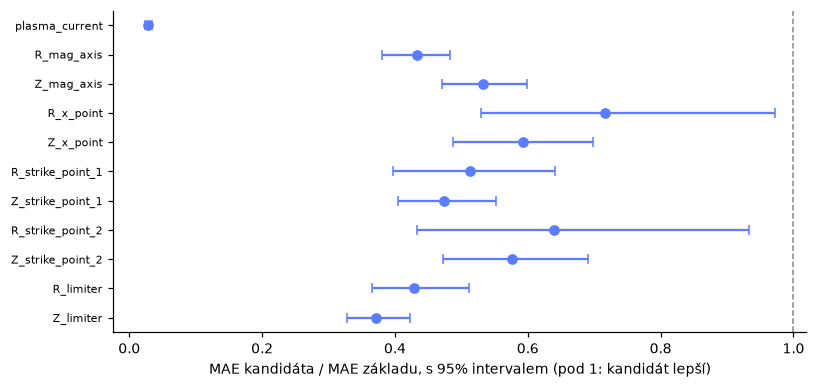

In [5]:
boot = F.bootstrap({"base": lk["base"]["clean"], "cand": lk["cand"]["clean"]}, yl, ml, gl, F.HEADLINE)
rows = []
for t in F.HEADLINE:
    c, b = boot["cand"][t], boot["base"][t]
    rows.append(dict(target=t, unit=F.UNIT[t][1], cand_MAE=c["mae"], cand_lo=c["mae_ci"][0], cand_hi=c["mae_ci"][1],
                     base_MAE=b["mae"], ratio=c["mae_ratio_vs_base"], ratio_lo=c["mae_ratio_ci"][0], ratio_hi=c["mae_ratio_ci"][1]))
bt = pd.DataFrame(rows).set_index("target")
print(bt.round(3).to_string())
KEY["bootstrap_ratio"] = {t: [round(bt.loc[t, "ratio"], 2), round(bt.loc[t, "ratio_lo"], 2), round(bt.loc[t, "ratio_hi"], 2)] for t in F.HEADLINE}
KEY["bootstrap_R_axis_ci"] = [round(bt.loc["R_mag_axis", "cand_lo"], 3), round(bt.loc["R_mag_axis", "cand_hi"], 3)]
print("\ncíle, u kterých interval poměru vylučuje 1:", [t for t in F.HEADLINE if bt.loc[t, "ratio_hi"] < 1])
proto("shlukový bootstrap po výbojích, 1 000 vzorků, 95% percentilové intervaly, na 30 odložených výbojích (tytéž modely jako výše).")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = np.arange(len(F.HEADLINE))[::-1]
ax.errorbar(bt.ratio, y, xerr=[bt.ratio - bt.ratio_lo, bt.ratio_hi - bt.ratio], fmt="o", color="#5b7cff", capsize=3)
ax.axvline(1, color="#888", lw=1, ls="--")
ax.set_yticks(y); ax.set_yticklabels(F.HEADLINE, fontsize=7)
ax.set_xlabel("MAE kandidáta / MAE základu, s 95% intervalem (pod 1: kandidát lepší)")
plt.tight_layout(); plt.show()

## 3. Je odložená sada snazší než zbytek? Vývojová křížová validace vedle ní

Na 119 vývojových výbojích se stejné dvě receptury hodnotily 5násobnou křížovou validací po výbojích (každý výboj odhaduje model, který na něm
neučil). Modely z křížové validace se učí na asi 95 výbojích, modely hodnocené na odložené sadě na 119, což té sadě trochu pomáhá.

In [6]:
cv = F.assemble("cv", RECS, 5)
for r in RECS:
    assert np.array_equal(cv[r]["idx"], dev_idx), "uložené predikce z křížové validace nepokrývají vývojové řádky"
D = {r: {c: F.pooled_stats(cv[r][c], Y[dev_idx], M[dev_idx]) for c in ("clean", "noisy")} for r in RECS}
rows = []
for t in F.HEADLINE:
    row = dict(target=t, unit=F.UNIT[t][1])
    for r in ("cand", "base"):
        d, l = D[r]["clean"][t]["mae"], L[r]["clean"][t]["mae"]
        row.update({f"{r}_dev_cv": d, f"{r}_locked": l, f"{r}_locked/dev": l / d})
    rows.append(row)
cmp_ = pd.DataFrame(rows).set_index("target")
print(cmp_.round(3).to_string())
n16 = {r: {"dev_cv": F.mean_nrmse(D[r]["clean"]), "locked": F.mean_nrmse(L[r]["clean"])} for r in ("cand", "base")}
print("\nprůměrné nRMSE přes 16 cílů (chyba vzhledem k rozptylu každého cíle):")
for r in ("cand", "base"):
    print(f"  {r:5s} vývojová CV {n16[r]['dev_cv']:.4f}  odložená {n16[r]['locked']:.4f}  -> odložená je o {100 * (1 - n16[r]['locked'] / n16[r]['dev_cv']):.0f} % nižší")
KEY["mean_nrmse16"] = {r: {k: round(v, 4) for k, v in n16[r].items()} for r in n16}
KEY["locked_lower_pct"] = {r: round(100 * (1 - n16[r]["locked"] / n16[r]["dev_cv"])) for r in n16}
KEY["R_axis_dev_cv"] = {r: round(D[r]["clean"]["R_mag_axis"]["mae"], 3) for r in ("cand", "base")}
proto("vývojová: 5násobný GroupKFold po výbojích uvnitř 119 vývojových výbojů, souhrn mimo učicí sadu, semínko = fold; odložená: modely učené na všech 119, hodnocené na 30; čisté vstupy; jedno semínko.")

                 unit  cand_dev_cv  cand_locked  cand_locked/dev  base_dev_cv  base_locked  base_locked/dev
target                                                                                                     
plasma_current     kA        0.033        0.034            1.036        1.509        1.199            0.794
R_mag_axis         mm        0.229        0.133            0.582        0.479        0.307            0.640
Z_mag_axis         mm        0.339        0.171            0.504        0.469        0.321            0.686
R_x_point          mm        0.210        0.115            0.549        0.253        0.161            0.636
Z_x_point          mm        0.191        0.096            0.503        0.235        0.162            0.690
R_strike_point_1   mm        0.208        0.109            0.524        0.313        0.212            0.679
Z_strike_point_1   mm        0.118        0.047            0.397        0.142        0.099            0.693
R_strike_point_2   mm       

Odložená sada je snazší pro obě receptury: průměrná relativní chyba je u každé o 35 % nižší a chyba radiální osy o 42 % (kandidát) a 36 % (základ) nižší.
Zlehčení není rovnoměrné. U kandidáta je to 40 až 60 % na ose, X bodu a dotykových bodech, ale žádné u proudu plazmatu (0,033 proti 0,035 kA)
a žádné u `R_limiter` (4,62 proti 4,55 mm). Číslo z odložené sady uvádějte spolu s křížovou validací; křížová validace je z těch dvou typičtější a
je také z náhodných skupinových foldů, které jsou podle oddílu 4 optimistické.

## 4. Výboje z pozdějších kampaní: blokové dělení

Čísla výbojů jsou chronologická, takže náhodné foldy vždy nechávají v učicí sadě sousední výboje téže kampaně. Blokové dělení
se učí na spodní polovině čísel vývojových výbojů (asi 60 výbojů) a testuje na horní polovině (asi 59), což je blíž
„výboji z pozdější kampaně“. Sloupec s náhodnými foldy je chyba křížové validace téže receptury na týchž 59 výbojích.

In [7]:
bl = F.assemble("blocked", RECS)
ids = np.unique(G[dev_idx]); upper = ids[len(ids) - len(ids) // 2:]
up_idx = bl["cand"]["idx"]
assert set(np.unique(G[up_idx])) == set(upper) and len(upper) == 59
B, S = {}, {}
for r in ("cand", "base"):
    assert np.array_equal(bl[r]["idx"], up_idx)
    B[r] = F.pooled_stats(bl[r]["clean"], Y[up_idx], M[up_idx])
    sel = np.isin(cv[r]["idx"], up_idx)
    S[r] = F.pooled_stats(cv[r]["clean"][sel], Y[cv[r]["idx"][sel]], M[cv[r]["idx"][sel]])
rows = []
for t in F.HEADLINE:
    row = dict(target=t, unit=F.UNIT[t][1])
    for r in ("cand", "base"):
        row.update({f"{r}_blocked": B[r][t]["mae"], f"{r}_random_same": S[r][t]["mae"], f"{r}_ratio": B[r][t]["mae"] / S[r][t]["mae"]})
    rows.append(row)
blk = pd.DataFrame(rows).set_index("target")
print(blk.round(3).to_string())
KEY["blocked_R_axis"] = {r: {"blocked": round(B[r]["R_mag_axis"]["mae"], 3), "random_same": round(S[r]["R_mag_axis"]["mae"], 3)} for r in ("cand", "base")}
KEY["blocked_ratio_range_cand"] = [round(float(blk["cand_ratio"].min()), 2), round(float(blk["cand_ratio"].max()), 2)]
proto("učeno na 60 nejnižších číslech vývojových výbojů, testováno na 59 nejvyšších (blokově); náhodné: chyby křížové validace téže receptury na těch 59 výbojích; čisté vstupy; jedno semínko.")

                 unit  cand_blocked  cand_random_same  cand_ratio  base_blocked  base_random_same  base_ratio
target                                                                                                       
plasma_current     kA         0.039             0.036       1.074         2.600             1.441       1.804
R_mag_axis         mm         0.396             0.215       1.840         1.231             0.448       2.747
Z_mag_axis         mm         0.430             0.206       2.091         0.820             0.405       2.023
R_x_point          mm         0.427             0.225       1.900         0.634             0.220       2.888
Z_x_point          mm         0.411             0.188       2.194         0.516             0.238       2.168
R_strike_point_1   mm         0.443             0.157       2.820         0.697             0.247       2.825
Z_strike_point_1   mm         0.198             0.086       2.296         0.311             0.132       2.356
R_strike_p

Učení na asi 60 místo asi 95 výbojích vysvětluje část rozdílu (křivka učení z `results/robustness-findings.md` ukazuje, že
chyba klesá zhruba na polovinu při zdvojnásobení dat), takže poměr je horní mez driftu mezi kampaněmi, ne jeho měření.

## 5. Obrázek: tytéž receptury ve třech protokolech

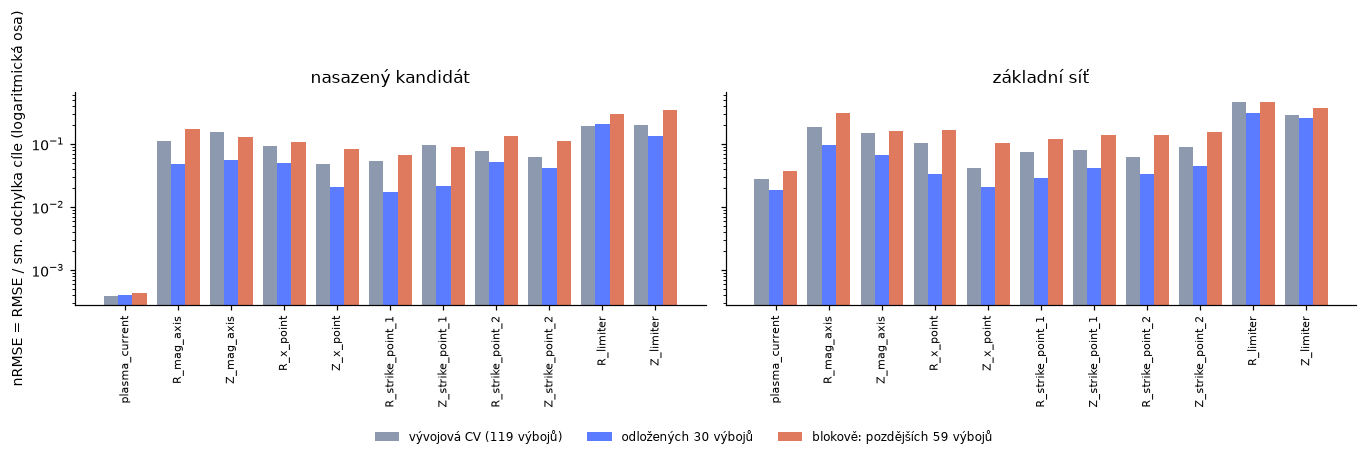


Protokol: nRMSE souhrnně přes řádky každé testovací sady; čisté vstupy; jedno semínko; tři testovací sady jsou různé výboje (viz tabulky výše).


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
xs = np.arange(len(F.HEADLINE)); w = 0.27
for ax, r, title in zip(axes, ("cand", "base"), ("nasazený kandidát", "základní síť")):
    ax.bar(xs - w, [D[r]["clean"][t]["nrmse"] for t in F.HEADLINE], w, label="vývojová CV (119 výbojů)", color="#8d99ae")
    ax.bar(xs, [L[r]["clean"][t]["nrmse"] for t in F.HEADLINE], w, label="odložených 30 výbojů", color="#5b7cff")
    ax.bar(xs + w, [B[r][t]["nrmse"] for t in F.HEADLINE], w, label="blokově: pozdějších 59 výbojů", color="#e07a5f")
    ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(F.HEADLINE, rotation=90, fontsize=7); ax.set_title(title)
axes[0].set_ylabel("nRMSE = RMSE / sm. odchylka cíle (logaritmická osa)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()
proto("nRMSE souhrnně přes řádky každé testovací sady; čisté vstupy; jedno semínko; tři testovací sady jsou různé výboje (viz tabulky výše).")

## 6. Přežije pořadí jiné semínko? Kontrola pěti semínek

Jedno semínko na model je slabina tabulek výše. `results/final-evaluation-seeds.md` přeučí základ a kandidáta se čtyřmi dalšími semínky na týchž
119 výbojích a jednou je ohodnotí na týchž 30 (bez změny receptury); semínko 0 je model výše. Tabulka se čte z té uložené zprávy.

In [9]:
txt = (RES / "final-evaluation-seeds.md").read_text()
pat = re.compile(r"\| (\w+) \((\w+)\) \| ([\d.e+-]+) \(([\d.e+-]+)\) \| ([\d.e+-]+) \(([\d.e+-]+)\) \| ([\d.]+) \| ([\d.]+) to ([\d.]+) \| (\d) of (\d) \| ([\d.]+) \|")
rows = []
for line in txt.splitlines():
    m = pat.match(line)
    if m:
        t, u, bm, bs, cm, cs, ratio, rlo, rhi, k, n, worst = m.groups()
        rows.append(dict(target=t, unit=u, base_mean=float(bm), base_sd=float(bs), cand_mean=float(cm), cand_sd=float(cs), ratio_of_means=float(ratio),
                         paired_ratio_min=float(rlo), paired_ratio_max=float(rhi), cand_better_in=f"{k} of {n}", worst_cand_over_best_base=float(worst)))
seeds = pd.DataFrame(rows).set_index("target")
assert len(seeds) == 7, "zpráva o semínkách změnila formát"
print(seeds.to_string())
# semínko 0 kontroly semínek je model tohoto notebooku: čísla se musí shodovat
for t in ("R_mag_axis", "Z_limiter"):
    r0 = L["cand"]["clean"][t]["mae"] / L["base"]["clean"][t]["mae"]
    inside = seeds.loc[t, "paired_ratio_min"] <= r0 <= seeds.loc[t, "paired_ratio_max"]
    print(f"semínko 0 tohoto notebooku, {t}: poměr {r0:.2f}, uvnitř rozsahu pěti semínek [{seeds.loc[t, 'paired_ratio_min']:.2f}, {seeds.loc[t, 'paired_ratio_max']:.2f}]: {inside}")
KEY["seeds"] = {t: {"base": [seeds.loc[t, "base_mean"], seeds.loc[t, "base_sd"]], "cand": [seeds.loc[t, "cand_mean"], seeds.loc[t, "cand_sd"]],
                    "ratio": seeds.loc[t, "ratio_of_means"], "worst_over_best": seeds.loc[t, "worst_cand_over_best_base"]} for t in seeds.index}
proto("5 semínek (0 až 4) na recepturu, každé učené na 119 vývojových výbojích a hodnocené na 30 odložených výbojích, čisté vstupy; průměr a sm. odchylka (n-1) přes semínka; čteno z results/final-evaluation-seeds.md.")

                 unit  base_mean  base_sd  cand_mean  cand_sd  ratio_of_means  paired_ratio_min  paired_ratio_max cand_better_in  worst_cand_over_best_base
target                                                                                                                                                     
R_mag_axis         mm      0.289    0.011     0.1330   0.0060            0.46              0.43              0.50         5 of 5                       0.50
Z_mag_axis         mm      0.330    0.021     0.1920   0.0160            0.58              0.54              0.67         5 of 5                       0.67
R_x_point          mm      0.141    0.015     0.1110   0.0066            0.79              0.71              0.96         5 of 5                       0.97
R_strike_point_2   mm      0.206    0.013     0.1160   0.0150            0.56              0.49              0.68         5 of 5                       0.72
R_limiter          mm     10.800    0.350     4.6800   0.3200   

Kandidát je lepší v každém semínku u všech sedmi cílů a jeho nejhorší semínko je všude pod nejlepším semínkem základu. Šum semínka je 3 až 13 % hodnoty, malý
proti zisku 40 až 60 % na ose, dotykovém bodu a bodu limiteru. Poloměr X bodu je slabý případ: zisk je 21 % a
nejhorší semínko kandidáta je jen o 3 % pod nejlepším semínkem základu. Proud plazmatu kandidáta má směrodatnou odchylku 0, protože pochází z ridge regrese,
která semínko nemá. Šum semínka nezahrnuje volbu 30 výbojů; to je bootstrap z oddílu 2.

## 7. Zašuměné vstupy: jiný model

Na zašuměném souboru organizátorů (bílý šum asi 0,155 rozptylu vstupu u cívek a 0,09 u smyček toku, žádný měřitelný drift; testy driftu
v `results/robustness-findings.md` používají náš vlastní syntetický model) nasazený kandidát **selhává**, protože rozdíly sousedních cívek šum
zesilují. Model pro zašuměné vstupy je základní síť učená s přidaným šumem a driftem (`base_aug`). Sloupce níže: modely učené na čistých datech
na zašuměných testovacích vstupech a model učený se šumem na čistých i na zašuměných vstupech.

In [10]:
cols = ["plasma_current", "R_mag_axis", "Z_mag_axis", "R_x_point", "R_limiter", "Z_limiter"]
spec = [("baseline (trained clean), clean inputs", "base", "clean"), ("baseline (trained clean), NOISY inputs", "base", "noisy"),
        ("shipped candidate (trained clean), NOISY inputs", "cand", "noisy"),
        ("noise-trained baseline, clean inputs", "base_aug", "clean"), ("noise-trained baseline, NOISY inputs", "base_aug", "noisy")]
noisy = pd.DataFrame({name: {t: L[r][c][t]["mae"] for t in cols} for name, r, c in spec}).T
noisy.columns = [f"{t} ({F.UNIT[t][1]})" for t in cols]
print(noisy.round(3).to_string())
dn = {name: {t: D[r][c][t]["mae"] for t in cols} for name, r, c in spec if r != "cand"}
print("\ntytéž modely ve vývojové křížové validaci (119 výbojů, mimo učicí sadu):")
d2 = pd.DataFrame(dn).T; d2.columns = noisy.columns; print(d2.round(3).to_string())
KEY["noisy_locked"] = {name: {t: round(v, 3) for t, v in noisy.loc[name].items()} for name in noisy.index}
proto("odložená: jednou učeno na 119 vývojových výbojích, testováno na 30; čisté = vstupy z equil_data.csv, ZAŠUMĚNÉ = dodané vstupy z equil_data_noisy.csv týchž řádků; jedno semínko; model učený se šumem vidí při učení šum 0,15 a drift 0,15 sm. odchylky každého vstupu.")

                                                 plasma_current (kA)  R_mag_axis (mm)  Z_mag_axis (mm)  R_x_point (mm)  R_limiter (mm)  Z_limiter (mm)
baseline (trained clean), clean inputs                         1.199            0.307            0.321           0.161          10.621          22.479
baseline (trained clean), NOISY inputs                         5.626            9.156            3.823           4.348          48.883          62.265
shipped candidate (trained clean), NOISY inputs                4.317          188.208          206.538          44.636        1294.639        1018.600
noise-trained baseline, clean inputs                           1.906            1.560            0.837           1.556          18.639          25.730
noise-trained baseline, NOISY inputs                           4.654            2.381            1.861           2.473          25.803          38.894

tytéž modely ve vývojové křížové validaci (119 výbojů, mimo učicí sadu):
                    

Modely učené se šumem se vzdávají shody s referenční rekonstrukcí na čistých vstupech (viz první a čtvrtý řádek), takže nasazená dvojice potřebuje vědět, jaký druh vstupu dostane;
jeden model nevyhrává v obou případech. Výjimkou je proud plazmatu: ridge regrese kandidáta, učená na čistých vstupech, dává na zašuměných vstupech pořád 4,31 kA
proti 4,65 kA u sítě učené se šumem. Převzetí proudu z toho ridge a všeho ostatního ze sítě učené se šumem se jako jedna receptura nespustilo.

## 8. Latence nasazené dvojice

Měří se čas, ne shoda s referencí: náhodné váhy natrénovaných tvarů, jeden vzorek, od 24 surových vstupů k 16 výstupům (`analysis/latency.py --shipped`).
Tabulka se čte z uložené zprávy `results/latency-shipped.md`.

In [11]:
lt = (RES / "latency-shipped.md").read_text()
hdr = re.search(r"CPU: ([^(]+)\((\d+) logical cores\).*?at the start (\[[^\]]+\]), at the end (\[[^\]]+\])", lt, re.S)
print(f"CPU: {hdr.group(1).strip()} ({hdr.group(2)} logických jader); zátěž (1, 5, 15 min) na začátku {hdr.group(3)}, na konci {hdr.group(4)}")
rowpat = re.compile(r"\| (\w+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \|")
lat = pd.DataFrame([dict(path=m.group(1), median_ms=float(m.group(2)), p99_ms=float(m.group(3))) for m in map(rowpat.match, lt.splitlines()) if m]).set_index("path")
lat = lat.loc[["numpy_end_to_end_diverted", "numpy_end_to_end_limited", "ipp1_final_predict_diverted", "ipp1_final_predict_limited", "mps_end_to_end_limited_with_transfers"]]
base_lat = [m for m in map(rowpat.match, (RES / "latency.md").read_text().splitlines()) if m and m.group(1) == "cpu_1_thread_single_sample"][0]
print(lat.to_string())
print(f"\nsamotná základní síť 24-16 (results/latency.md): medián {float(base_lat.group(2)):.4f} ms, p99 {float(base_lat.group(3)):.4f} ms")
KEY["latency_ms"] = {k: [lat.loc[k, "median_ms"], lat.loc[k, "p99_ms"]] for k in lat.index}
KEY["latency_baseline_ms"] = [float(base_lat.group(2)), float(base_lat.group(3))]
proto("jeden vzorek, jedno jádro CPU (numpy) nebo GPU od Applu s kopiemi; 5 000 měřených volání na řádek po zahřátí; stroj vytížený (zátěž 6 až 7), takže p99 je pesimistické a není to mez.")

CPU: Apple M5 (10 logických jader); zátěž (1, 5, 15 min) na začátku [7.01, 6.47, 8.13], na konci [6.68, 6.42, 8.1]
                                       median_ms  p99_ms
path                                                    
numpy_end_to_end_diverted                 0.0154  0.0571
numpy_end_to_end_limited                  0.0274  0.0930
ipp1_final_predict_diverted               0.0260  0.0650
ipp1_final_predict_limited                0.0544  0.1883
mps_end_to_end_limited_with_transfers     0.9837  2.4127

samotná základní síť 24-16 (results/latency.md): medián 0.0145 ms, p99 0.0209 ms

Protokol: jeden vzorek, jedno jádro CPU (numpy) nebo GPU od Applu s kopiemi; 5 000 měřených volání na řádek po zahřátí; stroj vytížený (zátěž 6 až 7), takže p99 je pesimistické a není to mez.


Cesta přes numpy je celý výpočet na vzorek: 22 rozdílů cívek, standardizace, obecná síť, ridge, rozhodnutí, (jen u limiterového případu)
síť pro limiter a zpětná standardizace. Nezahrnuje sběr a integraci signálů cívek, model učený se šumem potřebný pro zašuměné
vstupy ani operační systém reálného času; změřil se jen výpočet sítě, takže to není tvrzení o řídicí smyčce v reálném čase.

## 9. Klíčová čísla (čtou je závěry níže)

In [12]:
print("KEY_JSON", json.dumps(KEY))

KEY_JSON {"locked_discharges": 30, "locked_rows": 8761, "positive_polarity": {"development": 14, "locked": 2}, "locked_mae_cand": {"plasma_current": 0.0343, "R_mag_axis": 0.1331, "Z_mag_axis": 0.171, "R_x_point": 0.1153, "Z_x_point": 0.096, "R_strike_point_1": 0.1088, "Z_strike_point_1": 0.0468, "R_strike_point_2": 0.1354, "Z_strike_point_2": 0.0261, "R_limiter": 4.5573, "Z_limiter": 8.3629}, "locked_mae_base": {"plasma_current": 1.1986, "R_mag_axis": 0.3067, "Z_mag_axis": 0.3213, "R_x_point": 0.161, "Z_x_point": 0.1617, "R_strike_point_1": 0.2121, "Z_strike_point_1": 0.0986, "R_strike_point_2": 0.212, "Z_strike_point_2": 0.0454, "R_limiter": 10.6206, "Z_limiter": 22.4793}, "is_limited_accuracy_locked": {"cand": 0.9916, "base": 0.9892}, "max_rel_diff_to_report_pct": 1.88, "bootstrap_ratio": {"plasma_current": [0.03, 0.02, 0.03], "R_mag_axis": [0.43, 0.38, 0.48], "Z_mag_axis": [0.53, 0.47, 0.6], "R_x_point": [0.72, 0.53, 0.97], "Z_x_point": [0.59, 0.49, 0.7], "R_strike_point_1": [0.51, 

## Závěry

- **Nastavení.** 30 výbojů (8 761 řádků) odložených před konečnou volbou ze čtyř receptur, 119 vývojových výbojů (34 211 řádků) na učení; každý model učený na celých výbojích, 30 odložených výbojů (odložená testovací sada) hodnoceno jednou, souhrnně přes řádky. Notebook nic neučí: všechny metriky přepočítá z uložených predikcí a porovná 32 hodnot MAE s `results/final-evaluation.md` (na stroji, který zprávu vytvořil: žádný rozdíl nad její zaokrouhlení; na jiném stroji se přeučené sítě liší zhruba o šum semínka).
- **Shoda s referenční rekonstrukcí na 30 výbojích.** Nasazený kandidát, průměrná absolutní chyba, jedno semínko: `R_mag_axis` 0,133 mm (95% interval bootstrapu 0,099 až 0,177), `Z_mag_axis` 0,172 mm, `R_x_point` 0,115 mm, `R_strike_point_2` 0,136 mm, `R_limiter` 4,5 mm, `Z_limiter` 8,3 mm, proud plazmatu 0,035 kA, shoda `is_limited` 99,2 %. Základní síť má 0,307; 0,321; 0,161; 0,212; 10,6; 22,5 mm a 1,20 kA. Interval poměru vylučuje 1 u všech 11 hlavních cílů; nejslabší jsou `R_x_point` (0,72, interval 0,53 až 0,97) a `R_strike_point_2` (0,64, 0,43 až 0,94). Proud plazmatu je ridge regrese, ne síť (lineární model asi 43krát lepší než síť, `results/baseline.md`).
- **Uvádějte to s křížovou validací vedle.** Na 119 vývojových výbojích dávají tytéž receptury `R_mag_axis` 0,230 mm (kandidát) a 0,479 mm (základ) v 5násobné křížové validaci po výbojích. Odložená sada je snazší: průměrná relativní chyba přes 16 cílů je u obou receptur o 35 % nižší (0,0590 proti 0,0912 a 0,0803 proti 0,1228), chyba radiální osy o 42 % a 36 % nižší. Zlehčení se soustřeďuje na osu, X bod a dotykové body; proud plazmatu a `R_limiter` snazší nejsou. Jen 2 z 30 výbojů mají obrácený proud plazmatu (6,7 %, proti 14 ze 119 ve vývoji) a takové výboje nesou v `results/distribution.md` většinu čtvercové chyby osy. Hlavní číslo asi 0,2 mm na radiální ose je poctivější než 0,13 mm.
- **Neříkejte, že těch 30 výbojů nikdy nevidělo.** Těch 30 výbojů bylo odloženo před konečnou volbou ze čtyř receptur a po spatření čísel z odložené sady se žádná receptura neměnila, ale nápady za recepturou (rozdíly sousedních cívek, Huberova ztráta, síť pro limiter) se zkoušely na křížové validaci přes všech 149 výbojů, které těch 30 zahrnují. Říkejte „30 výbojů odložených před konečnou volbou modelu“.
- **Pozdější kampaně jsou těžší.** Při učení na spodní polovině čísel vývojových výbojů a testu na horní polovině (59 výbojů) je chyba radiální osy kandidáta 0,397 mm proti 0,216 mm u náhodných foldů na týchž výbojích a u hlavních cílů 1,07 až 2,83krát vyšší (základ: 1,231 proti 0,448 mm). Část rozdílu dělá menší učicí sada (asi 60 místo 95 výbojů), takže je to horní mez driftu mezi kampaněmi, ne jeho měření.
- **Pořadí přežije jiná semínka.** S pěti semínky na recepturu je kandidát lepší v každém semínku u všech sedmi kontrolovaných cílů a jeho nejhorší semínko je všude pod nejlepším semínkem základu. Šum semínka je 3 až 13 %; zisk je 40 až 60 % na ose, dotykovém bodě a bodu limiteru. `R_x_point` je slabý případ (zisk 21 %, nejhorší semínko kandidáta jen o 3 % pod nejlepším semínkem základu). Chyba proudu kandidáta má směrodatnou odchylku 0, protože je to ridge regrese.
- **Zašuměné vstupy potřebují jiný model.** Na zašuměném souboru organizátorů (bílý šum, žádný měřitelný drift) nasazený kandidát selhává (`R_mag_axis` 190 mm), protože rozdíly sousedních cívek šum zesilují. Model pro ně je základní síť učená s přidaným šumem a driftem: na 30 výbojích `R_mag_axis` 2,38 mm, `Z_mag_axis` 1,86 mm, limiter 25,8 a 38,9 mm, proud plazmatu 4,65 kA. Vzdává se shody s referenční rekonstrukcí na čistých vstupech (`R_mag_axis` 1,56 mm proti 0,307 mm), takže nasazená dvojice musí vědět, jaký druh vstupu dostane. Ridge pro proud drží 4,31 kA na zašuměných vstupech; kombinace toho ridge se sítí učenou se šumem se nespustila. Testy driftu používají náš vlastní syntetický drift, ne změřený.
- **Latence nasazené dvojice.** Od 24 surových vstupů k 16 výstupům v numpy na jednom jádru Apple M5: medián 0,0154 ms (divertorové, jen obecná síť) a 0,0274 ms (limiterové, obě sítě), p99 0,057 a 0,093 ms, proti 0,0145 ms pro samotnou základní síť; GPU potřebuje 0,98 ms na vzorek. Stroj byl vytížený (zátěž 6 až 7), takže p99 je pesimistické a není to mez. Sběr a integrace signálů cívek nejsou zahrnuty.
- **Co tento notebook neukazuje.** Výboje nového druhu (viz `results/unusual-shapes.md`: 1,2 až 2,4krát větší chyba, když se vynechá celá rodina tvarů), konec výboje, který je pro všechny receptury horší než střed (`results/final-evaluation.md`), a kameru.

## Vyzkoušejte model: `predict.py` na jednom odloženém výboji

Nasazený model běží i mimo tento notebook, jen s numpy (`predict.py` v kořeni repozitáře, kapitola README „Jak použít natrénovaný model“). Tady se jeden z 30 odložených výbojů zapíše do dočasného CSV s 24 vstupními sloupci, na něm se `predict.py` spustí jako samostatný proces a ukážou se tři řádky jeho výstupu. Výstupní soubor se přečte zpět a porovná s odhady téhož modelu spočítanými uvnitř tohoto notebooku. Exportovaný model (`out/model/clean-model.npz`, vytvořil ho `analysis/clean_model.py` ze 119 vývojových výbojů) obsahuje váhy odvozené z důvěrných dat a v gitu není.

In [13]:
import subprocess, tempfile, csv
sys.path.insert(0, str(repo))                                 # predict.py v kořeni repozitáře
import predict as P
model_file = C.OUT / "model" / "clean-model.npz"
assert model_file.exists(), "exportovaný model chybí: spusťte python run.py (nebo analysis/clean_model.py)"
one = lock_idx[gl == gl[0]]                                   # první odložený výboj
x_names = [c for c in df.columns if c.startswith(("IPR", "FL"))]
tmp = Path(tempfile.mkdtemp())
src_csv, out_csv = tmp / "input.csv", tmp / "estimates.csv"
with open(src_csv, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["discharge", "time"] + x_names)
    for i in one:
        w.writerow([int(G[i]), f"{df.time.values[i]:.9g}"] + [f"{v:.9g}" for v in X[i].astype(np.float64)])
run = subprocess.run([sys.executable, "-I", str(repo / "predict.py"), str(src_csv), "--model", str(model_file), "--out", str(out_csv)], capture_output=True, text=True)
assert run.returncode == 0, run.stderr
print(f"odložený výboj {int(G[one[0]])}: {len(one)} řádků přes predict.py jako samostatný proces (jen numpy)")
print(run.stderr.strip())
lines = out_csv.read_text().splitlines()
mid = 1 + len(one) // 2
print("\ntři řádky výstupu (mm; proud plazmatu v kA; buňky, které se pro konfiguraci nepoužijí, jsou prázdné):")
print("\n".join([lines[0]] + lines[mid:mid + 3]))
est = P.Model(model_file).estimates(X[one])
back = list(csv.reader(lines))[1:]
diff = max(abs(float(v) - est[r, j]) for r, row in enumerate(back) for j, v in enumerate(row[2:2 + est.shape[1]]) if v != "")
print(f"\nnejvětší rozdíl mezi výstupním souborem predict.py a odhady spočítanými v tomto notebooku: {diff:.2g} (mm, kA nebo bez jednotky; soubor má 8 platných číslic)")
KEY["predict_py"] = {"rows": int(len(one)), "max_abs_diff": float(diff)}
print("Protokol: model učený na 119 vývojových výbojích (semínko 0, receptura ipn), čisté vstupy, jeden odložený výboj; odhady jsou rekonstrukce ústavu, ne měření.")

odložený výboj 129: 259 řádků přes predict.py jako samostatný proces (jen numpy)
model: out/model/clean-model.npz
time per row: 76.8 us for the whole file at once, 85.6 us as the median of single-row calls (one CPU core, numpy only)

tři řádky výstupu (mm; proud plazmatu v kA; buňky, které se pro konfiguraci nepoužijí, jsou prázdné):
discharge,time,plasma_current_kA,R_mag_axis_mm,Z_mag_axis_mm,elongation,triangularity,triangularity_upper,triangularity_lower,R_x_point_mm,Z_x_point_mm,R_strike_point_1_mm,Z_strike_point_1_mm,R_strike_point_2_mm,Z_strike_point_2_mm,R_limiter_mm,Z_limiter_mm,is_limited,is_limited_flag
129,0.5,-238.53833,553.2853,28.371871,1.8203068,0.36911434,0.24903372,0.48897421,463.43964,-319.90504,425.82235,-350.26297,490.62684,-352.97856,,,-0.00067418814,0
129,0.503875969,-238.77327,553.1857,28.351415,1.8207523,0.36941275,0.2493459,0.48925605,463.32109,-319.83584,425.66749,-350.18691,490.57072,-352.99274,,,-0.00062429905,0
129,0.507751938,-238.88448,553.18683,28.298032


největší rozdíl mezi výstupním souborem predict.py a odhady spočítanými v tomto notebooku: 5e-06 (mm, kA nebo bez jednotky; soubor má 8 platných číslic)
Protokol: model učený na 119 vývojových výbojích (semínko 0, receptura ipn), čisté vstupy, jeden odložený výboj; odhady jsou rekonstrukce ústavu, ne měření.


## Nasazený model dnes: měření dělená proudem plazmatu

Pole cívek je úměrné proudům, takže tvar závisí na poměrech měření k proudu plazmatu, ne na jejich velikosti. Proud plazmatu je znám jen ze vstupů
(ridge na 24 měřeních), takže se každé měření jím vydělí a proud je jeden vstup navíc; bod limiteru odpovídá síť, která nejdřív rozhodne o straně nádoby (nahoře nebo dole).
`analysis/clean_model.py` ji učí na týchž 119 vývojových výbojích (`results/clean-model.md`); soubor `out/model/clean-model.npz` se tu čte, nebo tu učí (pod minutu), pokud ho `run.py` neexportoval.

**Výhrada.** Těch 30 odložených výbojů se hodnotilo pro dřívější receptury, než se tato ustálila na vývojové sadě, takže to není čerstvá testovací sada. Jedno semínko, jedno měření.

In [14]:
sys.path.insert(0, str(repo))                       # predict.py v kořeni repozitáře
import clean_model as IPN
from predict import Model as ShippedModel
npz = C.OUT / "model" / "clean-model.npz"
if npz.exists():
    ipn = ShippedModel(npz)
    src = f"přečteno z {npz.name}"
else:
    arr = IPN.train(X[dev_idx], Y[dev_idx], "diff2", 150)
    tmp = C.OUT / "model" / "clean-model-notebook.npz"
    tmp.parent.mkdir(parents=True, exist_ok=True)
    np.savez(tmp, **arr, input_names=np.array([c for c in df.columns if c.startswith(("IPR", "FL"))]), output_names=np.array(C.TARGETS),
             output_scales=np.array([C.UNIT[t][0] for t in C.TARGETS]), limiter_columns=np.array(F.LIMITER), plasma_current_column=np.array(J["plasma_current"]),
             is_limited_column=np.array(J["is_limited"]), ipn=np.array(1), ip_scale=np.array(IPN.CURRENT_SCALE), feature_mode=np.array("diff2"))
    ipn = ShippedModel(tmp)
    src = "naučeno v tomto notebooku"
S_ipn = F.pooled_stats(ipn.predict(X[lock_idx]), yl, ml)
rows = []
for t in C.TARGETS:
    a, b, c = L["base"]["clean"][t], L["cand"]["clean"][t], S_ipn[t]
    rows.append(dict(target=t, unit=c["unit"] or "-", base_MAE=a["mae"], cand_MAE=b["mae"], ipn_MAE=c["mae"], ipn_over_cand=c["mae"] / b["mae"],
                     ipn_p99=c["p99"], ipn_max=c["max"]))
today = pd.DataFrame(rows).set_index("target")
print("nasazený model dnes:", src)
print(today.round(4).to_string())
acc = {k: 100 * (1 - F.mean_nrmse(v)) for k, v in (("baseline", L["base"]["clean"]), ("cand", L["cand"]["clean"]), ("ipn (nasazený dnes)", S_ipn))}
print("\ncelková přesnost, 100 x (1 - průměrné nRMSE přes 16 výstupů):", {k: round(v, 2) for k, v in acc.items()})
KEY["locked_mae_ipn"] = {t: round(S_ipn[t]["mae"], 4) for t in F.HEADLINE}
KEY["overall_accuracy_locked"] = {k: round(v, 2) for k, v in acc.items()}

nasazený model dnes: přečteno z clean-model.npz
                    unit  base_MAE  cand_MAE  ipn_MAE  ipn_over_cand  ipn_p99   ipn_max
target                                                                                 
plasma_current        kA    1.1986    0.0343   0.0343         1.0000   0.1399    0.3840
R_mag_axis            mm    0.3067    0.1331   0.0562         0.4221   0.3643   11.7981
Z_mag_axis            mm    0.3213    0.1710   0.0647         0.3781   0.4129   19.5849
elongation             -    0.0044    0.0028   0.0012         0.4163   0.0089    0.1720
triangularity          -    0.0022    0.0013   0.0008         0.5914   0.0037    0.0491
triangularity_upper    -    0.0026    0.0015   0.0012         0.7713   0.0038    0.1144
triangularity_lower    -    0.0030    0.0018   0.0009         0.4885   0.0059    0.0590
R_x_point             mm    0.1610    0.1153   0.0472         0.4093   0.4793    3.2639
Z_x_point             mm    0.1617    0.0960   0.0526         0.5483   0

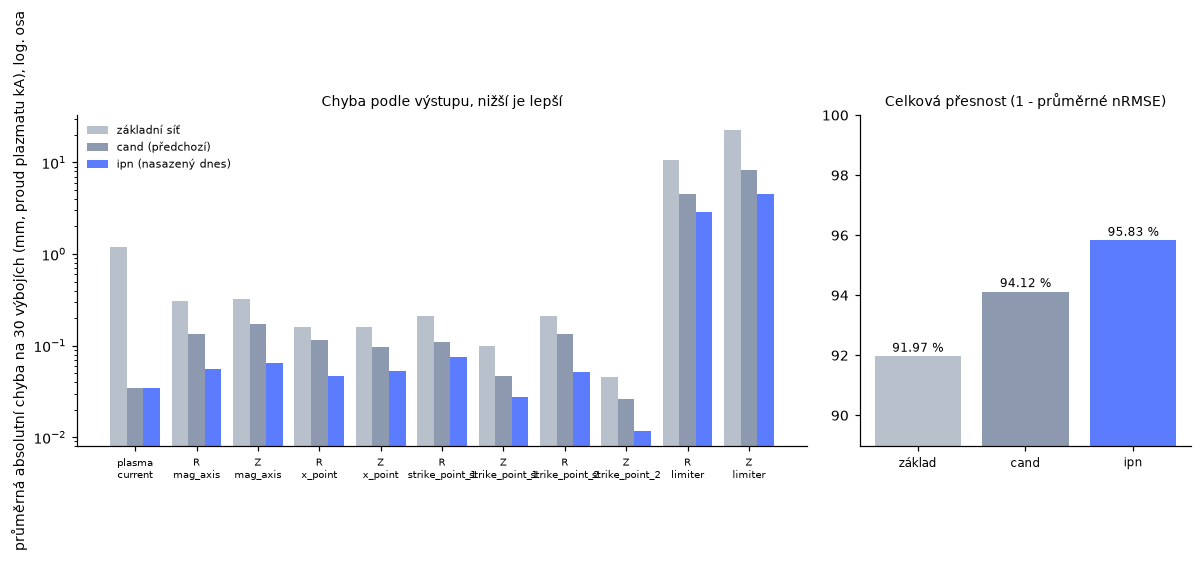

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
names = [t for t in F.HEADLINE]
x = np.arange(len(names)); w = 0.27
for k, (col, lab, colr) in enumerate((("base_MAE", "základní síť", "#b8c0cc"), ("cand_MAE", "cand (předchozí)", "#8d99ae"), ("ipn_MAE", "ipn (nasazený dnes)", "#5b7cff"))):
    ax[0].bar(x + (k - 1) * w, [today.loc[t, col] * (1.0 if today.loc[t, "unit"] != "kA" else 1.0) for t in names], w, label=lab, color=colr)
ax[0].set_yscale("log"); ax[0].set_xticks(x); ax[0].set_xticklabels([t.replace("_", "\n", 1) for t in names], fontsize=6.5)
ax[0].set_ylabel("průměrná absolutní chyba na 30 výbojích (mm, proud plazmatu kA), log. osa")
ax[0].set_title("Chyba podle výstupu, nižší je lepší", fontsize=9); ax[0].legend(fontsize=7, frameon=False)
vals = list(acc.values())
ax[1].bar(range(3), vals, color=["#b8c0cc", "#8d99ae", "#5b7cff"])
for i, v in enumerate(vals):
    ax[1].text(i, v + 0.15, f"{v:.2f} %", ha="center", fontsize=8)
ax[1].set_ylim(min(vals) - 3, 100); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["základ", "cand", "ipn"], fontsize=8)
ax[1].set_title("Celková přesnost (1 - průměrné nRMSE)", fontsize=9)
plt.tight_layout(); plt.show()

**Průměry skrývají chvosty.** Průměrná chyba osy je pár setin milimetru, ale průměr neříká nic o nejhorších řádcích. Tabulka uvádí průměr, medián, 99. percentil a nejhorší jednotlivý řádek
nasazeného modelu na 30 výbojích pro osu a pro bod limiteru, zvlášť pro limiterovou a divertorovou konfiguraci.

In [16]:
pred = ipn.predict(X[lock_idx]) * ipn.scales
limited = Y[lock_idx, J["is_limited"]] > 0.5
rows = []
for t in ("R_mag_axis", "Z_mag_axis", "R_limiter", "Z_limiter"):
    j = J[t]
    for name, sel in (("all rows", np.ones(len(lock_idx), bool)), ("limited", limited), ("divertor", ~limited)):
        k = sel & ml[:, j]
        if k.sum() == 0:
            continue
        e = np.abs(pred[k, j] - yl[k, j] * ipn.scales[j])
        rows.append(dict(target=t, rows=name, n=int(k.sum()), mean=e.mean(), median=np.median(e), p99=np.percentile(e, 99), worst=e.max()))
tails = pd.DataFrame(rows).set_index(["target", "rows"])
print("chyba v mm na 30 odložených výbojích, nasazený model dnes")
print(tails.round(3).to_string())
ra = tails.loc[("R_mag_axis", "limited"), "mean"] / tails.loc[("R_mag_axis", "divertor"), "mean"]
za = tails.loc[("Z_mag_axis", "limited"), "mean"] / tails.loc[("Z_mag_axis", "divertor"), "mean"]
print(f"\nlimiterové řádky proti divertorovým, průměrná chyba osy: R {ra:.2f}krát, Z {za:.2f}krát")
KEY["tails_ipn"] = {f"{t}/{r}": {k: round(float(v), 3) for k, v in tails.loc[(t, r)][["mean", "median", "p99", "worst"]].items()} for t, r in tails.index}

chyba v mm na 30 odložených výbojích, nasazený model dnes
                        n   mean  median     p99    worst
target     rows                                          
R_mag_axis all rows  8761  0.056   0.032   0.364   11.798
           limited   3554  0.071   0.041   0.556   11.798
           divertor  5207  0.046   0.026   0.298    0.918
Z_mag_axis all rows  8761  0.065   0.036   0.413   19.585
           limited   3554  0.087   0.040   0.720   19.585
           divertor  5207  0.050   0.033   0.214    1.723
R_limiter  all rows  3554  2.846   0.331  35.188  351.617
           limited   3554  2.846   0.331  35.188  351.617
Z_limiter  all rows  3554  4.486   1.296  52.299  439.198
           limited   3554  4.486   1.296  52.299  439.198

limiterové řádky proti divertorovým, průměrná chyba osy: R 1.53krát, Z 1.74krát


**Přesnost každého výstupu.** Přesnost = 100 x (1 - nRMSE): odmocnina ze střední čtvercové chyby výstupu dělená rozptylem referenční rekonstrukce na týchž řádcích, takže 100 % je přesná kopie.
Grafy vyrábí `analysis/plot_accuracy.py` (české verze jsou vedle nich v `results/`). Protože RMSE silně váží velké chyby, může bod limiteru vypadat tady hůř, než naznačuje jeho průměrná chyba v mm:
pár řádků s chybami stovek mm stojí víc přesnosti, než jí přinese mnoho řádků s chybami několika mm. Bod limiteru je také místo, kde je nasazený model nejméně přesný.

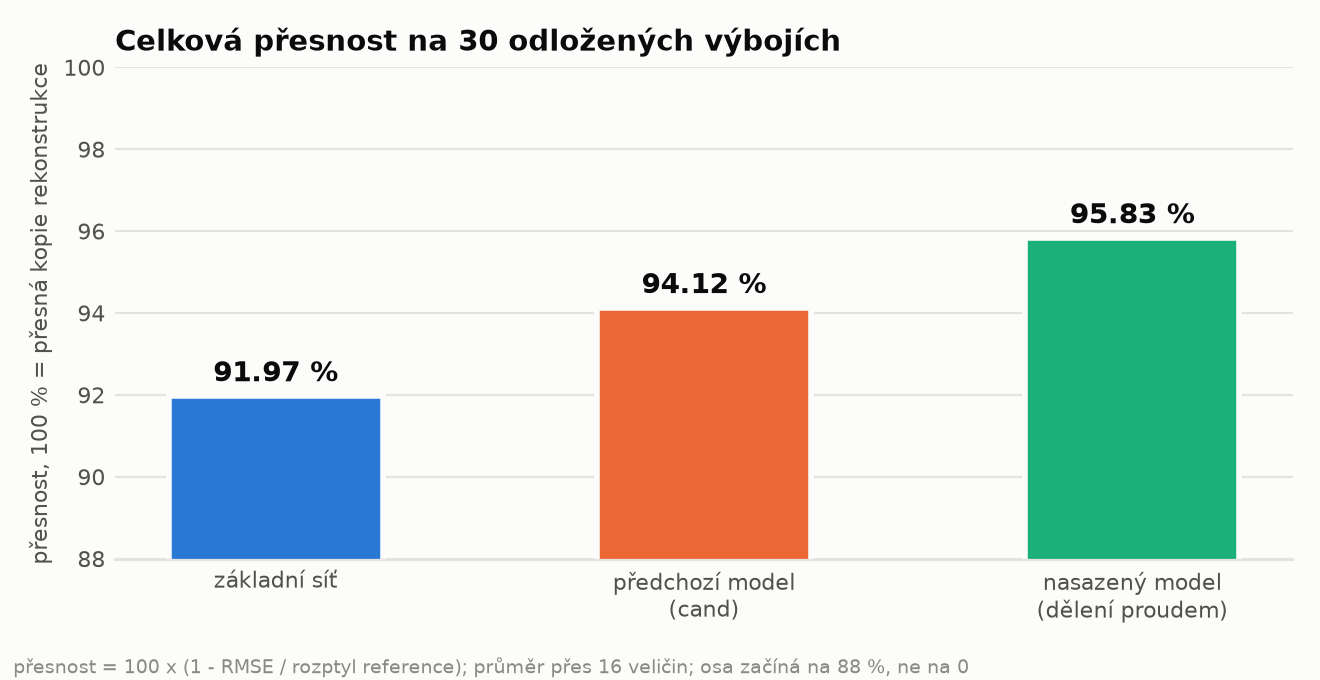

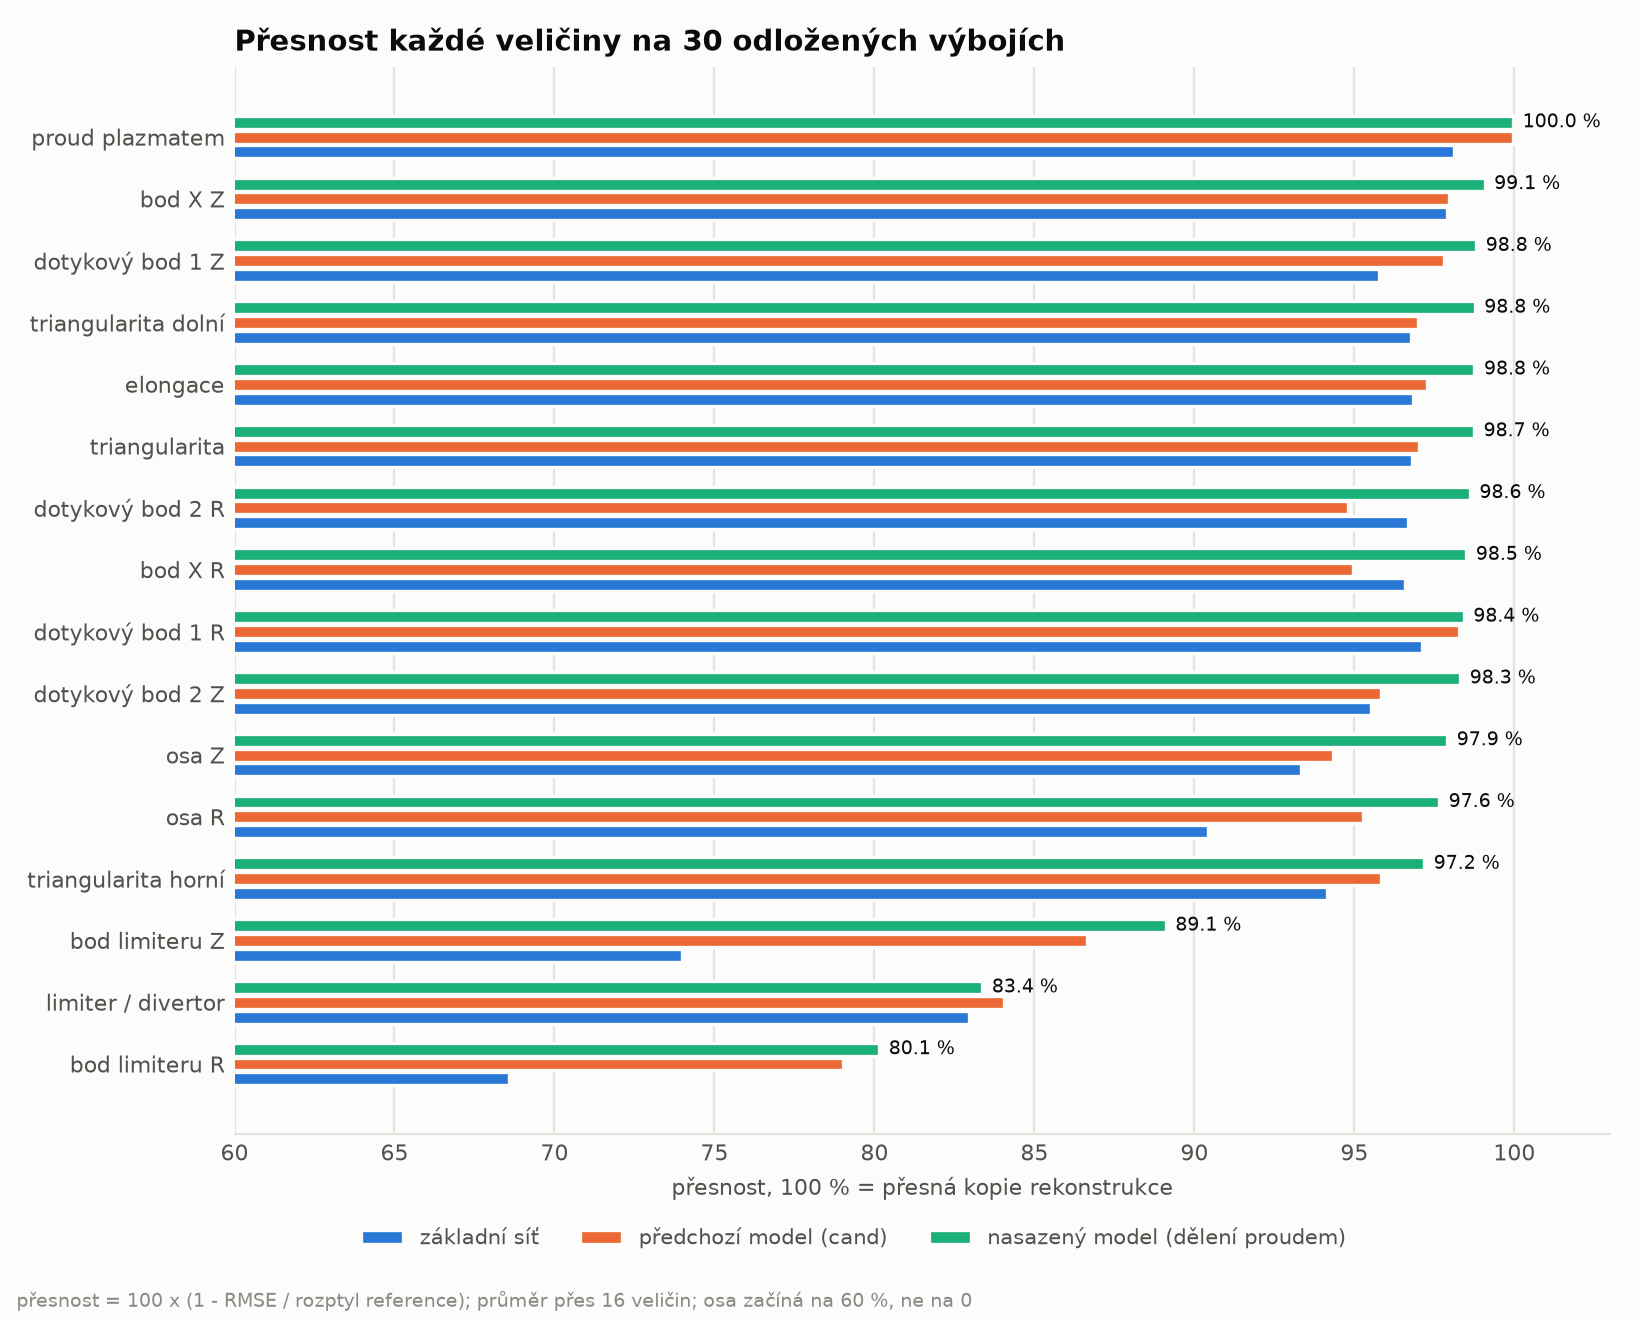

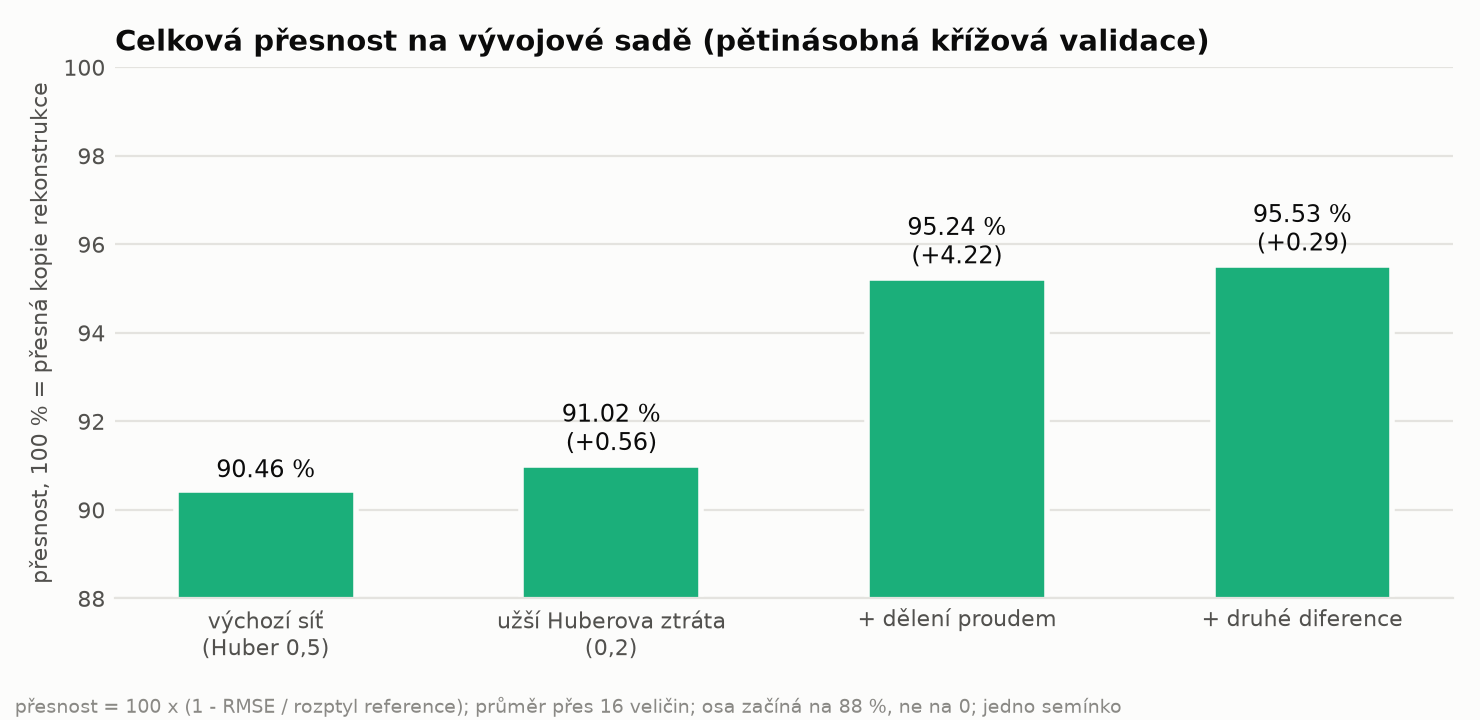

přesnost podle výstupu, %
                     základ  cand (předchozí)  ipn (nasazený)
plasma_current         98.1             100.0           100.0
R_mag_axis             90.4              95.3            97.6
Z_mag_axis             93.3              94.3            97.9
elongation             96.8              97.3            98.8
triangularity          96.8              97.0            98.7
triangularity_upper    94.1              95.8            97.2
triangularity_lower    96.8              97.0            98.8
R_x_point              96.6              95.0            98.5
Z_x_point              97.9              98.0            99.1
R_strike_point_1       97.1              98.3            98.4
Z_strike_point_1       95.8              97.8            98.8
R_strike_point_2       96.7              94.8            98.6
Z_strike_point_2       95.5              95.8            98.3
R_limiter              68.6              79.0            80.1
Z_limiter              74.0              86.

In [17]:
import plot_accuracy as PA
from IPython.display import Image, display
acc = {"base": PA.accuracy(L["base"]["clean"]), "cand": PA.accuracy(L["cand"]["clean"]), "ipn": PA.accuracy(S_ipn)}
tmp = C.OUT / "figs"; tmp.mkdir(exist_ok=True)
overall = PA.overall_chart(acc, "cs", tmp / "overall.png")
PA.outputs_chart(acc, "cs", tmp / "outputs.png")
ladder = PA.ladder_chart("cs", tmp / "ladder.png")
for name in ("overall", "outputs", "ladder"):
    display(Image(filename=str(tmp / f"{name}.png"), width=700 if name == "outputs" else 620))
table = pd.DataFrame(acc).round(1)
table.columns = ["základ", "cand (předchozí)", "ipn (nasazený)"]
print("přesnost podle výstupu, %"); print(table.to_string())

## Příloha. Navíc: specialista na limiter, ne nasazený model

Nejslabším cílem nasazeného modelu je bod limiteru. `results/limiter-swap.md` zkouší pro něj ještě jeden krok: síť pro limiter z `cand` (síť, která odpovídá `R_limiter` a `Z_limiter`,
když je plazma limiterové) se nahradí reziduální sítí z nejlepšího pokusu cloudového hledání modelu a nic jiného se nemění. **Je to výsledek navíc. Není to nasazený model:** všechno
před touto přílohou a každé číslo na slajdech je pro `cand`. Čísla níže se čtou z uložené zprávy, nepřepočítávají se tady (sítě pro limiter nejsou v cache, kterou tento notebook používá).

In [18]:
txt = (RES / "limiter-swap.md").read_text()
arm_pat = re.compile(r"\| (arm \d)[^|]*\| ([\d.]+) \(([\d.]+)\) \| ([\d.]+) \(([\d.]+)\) \| ([^|]*)\| ([^|]*)\|")
arms = {m.group(1): dict(R_limiter_mm=float(m.group(2)), R_sd=float(m.group(3)), Z_limiter_mm=float(m.group(4)), Z_sd=float(m.group(5)), gain_R=m.group(6).strip() or "-", gain_Z=m.group(7).strip() or "-")
        for m in map(arm_pat.match, txt.splitlines()) if m}
names = {"arm 0": "cand (nasazený)", "arm 1": "cand + reziduální síť pro limiter", "arm 2": "kontrola: vlastní síť, váha 1,5, 100 epoch"}
dev = pd.DataFrame(arms).T.rename(index=names)
print("Vývoj: 119 výbojů, 5 foldů x 3 semínka, souhrnné MAE mimo učicí sadu v mm, průměr a sm. odchylka přes semínka")
print(dev.to_string())
lock = {m.group(1): (float(m.group(2)), float(m.group(3)), int(m.group(4))) for m in re.finditer(r"\| (R_limiter|Z_limiter) \(mm\) \| ([\d.]+) \| ([\d.]+) \| ([+-]?\d+) %", txt)}
print("\nOdložených 30 výbojů, hodnoceno jednou (semínko 0), MAE v mm:")
print(pd.DataFrame(lock, index=["cand", "cand + reziduální síť pro limiter", "změna (%)"]).T.to_string())
lat = re.search(r"\*\*median of the 5 runs\*\* \| \| \*\*([\d.]+)\*\* \| \*\*([\d.]+)\*\* \| \*\*([\d.]+)\*\*", txt)
print(f"\nMediánová latence limiterové cesty, 5 běhů s běžnou prioritou (ms): cand {float(lat.group(1)):.4f}, s reziduální sítí pro limiter {float(lat.group(2)):.4f}, kontrola {float(lat.group(3)):.4f}")
# čísla citovaná v textu níže se tu kontrolují, aby se text nemohl rozejít se zprávou
assert (arms["arm 0"]["R_limiter_mm"], arms["arm 1"]["R_limiter_mm"], arms["arm 0"]["Z_limiter_mm"], arms["arm 1"]["Z_limiter_mm"]) == (4.85, 2.98, 12.2, 7.44)
assert lock == {"R_limiter": (4.55, 3.26, -28), "Z_limiter": (8.35, 5.55, -34)} and (float(lat.group(1)), float(lat.group(2))) == (0.029, 0.0872)
KEY["extra_limiter"] = {"dev": {k: [v["R_limiter_mm"], v["Z_limiter_mm"]] for k, v in arms.items()}, "locked": lock, "latency_ms": [float(lat.group(1)), float(lat.group(2))]}
print("\nProtokoly: vývoj = 5násobný GroupKFold po výbojích uvnitř 119 vývojových výbojů, 3 semínka, párové foldy a semínka; odložená = učeno na 119, jednou hodnoceno na 30; čisté vstupy; všechny ostatní výstupy shodné s cand.")

Vývoj: 119 výbojů, 5 foldů x 3 semínka, souhrnné MAE mimo učicí sadu v mm, průměr a sm. odchylka přes semínka
                                           R_limiter_mm  R_sd Z_limiter_mm  Z_sd gain_R gain_Z
cand (nasazený)                                    4.85  0.25         12.2  0.45      -      -
cand + reziduální síť pro limiter                  2.98  0.14         7.44  0.38   39 %   39 %
kontrola: vlastní síť, váha 1,5, 100 epoch         5.11  0.26         12.4  0.33   -5 %   -1 %

Odložených 30 výbojů, hodnoceno jednou (semínko 0), MAE v mm:
           cand  cand + reziduální síť pro limiter  změna (%)
R_limiter  4.55                               3.26      -28.0
Z_limiter  8.35                               5.55      -34.0

Mediánová latence limiterové cesty, 5 běhů s běžnou prioritou (ms): cand 0.0290, s reziduální sítí pro limiter 0.0872, kontrola 0.0296

Protokoly: vývoj = 5násobný GroupKFold po výbojích uvnitř 119 vývojových výbojů, 3 semínka, párové foldy a semínka; odložená

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, t, col in zip(ax, ("R_limiter", "Z_limiter"), ("R_limiter_mm", "Z_limiter_mm")):
    vals = [dev.loc[names["arm 0"], col], dev.loc[names["arm 1"], col], lock[t][0], lock[t][1]]
    a.bar([0, 1, 2.6, 3.6], vals, color=["#8d99ae", "#5b7cff", "#8d99ae", "#5b7cff"])
    a.set_xticks([0.5, 3.1]); a.set_xticklabels(["vývoj\n(křížová validace)", "30 odložených\nvýbojů"], fontsize=8)
    a.set_title(t + " (mm): šedě cand, modře s reziduální sítí pro limiter", fontsize=8); a.set_ylabel("MAE (mm)")
plt.tight_layout(); plt.show()

/tmp/ipykernel_65675/143060478.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


**Ještě jeden krok pro nejslabší cíl.** Reziduální síť pro limiter snižuje chybu limiteru o 39 % ve vývoji (`R_limiter` 4,85 na 2,98 mm, `Z_limiter` 12,2 na 7,44 mm) a o 28 a 34 % na 30 odložených
výbojích (4,55 na 3,26 mm a 8,35 na 5,55 mm), za zhruba trojnásobnou cenu té sítě (medián limiterové cesty 0,087 ms proti 0,029 ms). **Jako hlavní model se nepřijímá**, protože její nastavení
pochází z hledání, které vidělo všech 149 výbojů včetně odložených, takže druhé číslo je kontrola, že vývojový zisk nezmizel, a ne čistý důkaz. Nic dalšího se nemění: všechny ostatní výstupy
(osa, X bod, dotykové body, proud plazmatu, `is_limited`) jsou stejné jako u `cand`.

Dvě meze postupu. (1) Předem napsané pravidlo pokusu říkalo, že nikdo nevyhrává, protože větev 1 neprošla kritériem latence (0,1 ms) ve dvou během s nízkou prioritou na vytíženém stroji; vedoucí to kritérium
dodatečně upravil (medián z 5 běhů s běžnou prioritou) a zpráva to označuje jako post hoc. (2) Kontrola, tedy vlastní síť `cand` se stejnou váhou ztráty a počtem epoch, nedala žádný zisk (o 5 a 1 % horší), takže
tato dvě nastavení důvodem nejsou a která další část reziduální sítě zisk nese, se neoddělilo.